# 04.5 — Interlaced SSB on *thick* specimens (multislice)

Notebook 04 established that a checkerboard-interlaced acquisition puts the light-on / light-off
*difference* on a carrier at the **scan Nyquist frequency**, so that `fftshift`-ing the scan-Fourier
transform of the virtual-BF stack demodulates it and ordinary SSB returns $\Delta\phi$ directly.

That demonstration used a **single projected phase slice** — i.e. exactly the weak, thin-object
regime SSB is derived in. Real flakes are not single layers. This notebook asks how far the trick
survives dynamical scattering.

**Setup.** The specimen is a stack of $N$ identical *base* (light-off) layers spaced by the hBN
interlayer distance $d = c/2 = 3.33\ \mathrm{Å}$. The light-on state differs from the light-off
state in **one layer only — the top (entrance) layer**, which carries the same apodized excitation
phase used in notebook 04. Everything else is identical, so the ground-truth $\Delta\phi$ is
independent of $N$ and the only thing that changes with thickness is how badly the $N-1$ layers
*underneath* scramble it.

Each thickness is reconstructed **noise-free and at a finite dose**, so the two failure modes can
be told apart: dynamical scattering (systematic) versus shot noise (statistical). The demodulated
excitation lives on a carrier at the very edge of the scan bandwidth, which is exactly where Poisson
noise is white and unattenuated -- so it is a priori the more fragile of the two.

**Pipeline per (thickness, dose).**
1. abTEM multislice → 4D-STEM cube for the light-off stack and for the light-on stack.
2. Poisson-sample each cube *independently* at the requested dose (each physical scan position is
   measured exactly once, so off and on positions must get independent realisations).
3. Checkerboard-interlace the two cubes into one merged acquisition.
4. Baseband SSB → mean object; `fftshift`-demodulated SSB → $\Delta\phi$.
5. Compare against ground truth (Pearson $r$ + recovered amplitude).

Two demodulated reconstructions are compared: the notebook-04 form (mean of per-BF-pixel phase
angles) and the closed-form estimator now in `method_wrappers.direct_ssb`, which averages the
bright-field pixels *coherently* and solves $\Delta\phi = 2\arctan\,\mathrm{Im}(\delta O / \bar{O})$.

In [1]:
import time
import pickle

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
from scipy.stats import binned_statistic

import abtem
from abtem import PixelatedDetector
from abtem.core.energy import energy2sigma, energy2wavelength
from abtem.potentials.iam import PotentialArray
from abtem.scan import GridScan
from abtem.waves import Probe

from quantem.core.datastructures import Dataset4d
from quantem.diffractive_imaging.direct_ptychography import DirectPtychography

import method_wrappers as mw

# --- acquisition (identical to notebook 04) ---------------------------------
ACC_VOLTAGE     = 60e3   # eV
PROBE_SEMIANGLE = 30     # mrad
PROBE_DEFOCUS   = 0      # Å -- focus on the entrance plane, i.e. on the excited layer
SCAN_STEP_SIZE  = 0.15   # Å, native (interlaced) step

# --- specimen ---------------------------------------------------------------
D_INTERLAYER    = 3.33   # Å, hBN c/2
N_LAYERS_SWEEP  = [1, 2, 4, 8, 16, 32]
EXCITED_LAYER   = 0      # slice index of the light-on layer; 0 == entrance == "top"

# --- dose --------------------------------------------------------------------
# None == noise-free. Finite values are electrons / Å^2 of scanned area; abTEM
# converts to counts per diffraction pattern via the scan pixel area.
DOSES = [None, 1e6]
NOISE_SEED = 12345

# --- keep the datacubes small: SSB only ever touches the bright-field disk ---
DET_CROP        = 64     # detector pixels kept around the optical axis

SIGMA = float(energy2sigma(ACC_VOLTAGE))
WAVELENGTH = float(energy2wavelength(ACC_VOLTAGE))
print(f"sigma = {SIGMA:.4e} 1/(V Å),  lambda = {WAVELENGTH:.4f} Å")
for _dose in DOSES:
    if _dose is not None:
        print(f"dose {_dose:.0e} e/Å² -> ~{_dose * SCAN_STEP_SIZE**2:,.0f} electrons per diffraction pattern")

cuda:0
sigma = 1.1357e-03 1/(V Å),  lambda = 0.0487 Å
dose 1e+06 e/Å² -> ~22,500 electrons per diffraction pattern


In [2]:
with open("bcenters_base_excited_phases_wide_fov.pkl", "rb") as f:
    data = pickle.load(f)

base_phase = data["base"]
x, y = data["x"], data["y"]
dx = float(x[1] - x[0])
dy = float(y[1] - y[0])

# Same apodization as notebook 04: taper the excitation to zero at the edges so it
# never interacts with the periodic boundary of the multislice supercell.
hamming = np.outer(np.hamming(base_phase.shape[0]), np.hamming(base_phase.shape[1]))
delta_phi_gt = (data["excited"] - base_phase) * hamming
excited_phase = base_phase + delta_phi_gt

print(f"grid {base_phase.shape}, sampling {dx:.4f} Å, FOV {base_phase.shape[0]*dx:.3f} Å")
print(f"single-layer base phase   : [{base_phase.min():+.4f}, {base_phase.max():+.4f}] rad")
print(f"single-layer excitation Δφ: [{delta_phi_gt.min():+.4f}, {delta_phi_gt.max():+.4f}] rad")

grid (251, 251), sampling 0.0960 Å, FOV 24.096 Å
single-layer base phase   : [-0.0372, +0.1970] rad
single-layer excitation Δφ: [-0.0211, +0.0129] rad


## Building the stack and simulating

`PotentialArray` wants projected potential in V·Å per slice; our layers are phase maps, so each
slice is `phase / sigma`. `slice_thickness` is the propagation distance between layers — set to the
hBN interlayer spacing. A stack of $N$ layers therefore has a physical thickness of $N \cdot d$ and
a *total projected* phase of $N \times$ the single-layer phase, which is what pushes the specimen
out of the weak-phase regime as $N$ grows.

Note this is a deliberately idealised stack: every layer is an exact copy of the same projected
potential, with no AA′ registry shift between layers. That maximises channelling along the atomic
columns, so it is if anything a *pessimistic* test of the method.

In [3]:
def stack_potential(n_layers, excited_layer=None):
    '''Stack of `n_layers` base layers; `excited_layer` (if not None) is swapped
    for the light-on layer. Slice separation = hBN interlayer spacing.'''
    layers = [base_phase] * n_layers
    if excited_layer is not None:
        layers = list(layers)
        layers[excited_layer] = excited_phase
    array = np.stack([layer / SIGMA for layer in layers]).astype(np.float32)
    return PotentialArray(array=array, slice_thickness=D_INTERLAYER, sampling=(dx, dy))


def simulate_scan(potential, scan_step=SCAN_STEP_SIZE, defocus=PROBE_DEFOCUS):
    '''Full multislice 4D-STEM scan over the whole supercell.

    Returns the (uncropped) abTEM measurement, so that Poisson noise can be drawn
    from the complete diffraction pattern before any detector cropping.
    '''
    probe = Probe(energy=ACC_VOLTAGE, semiangle_cutoff=PROBE_SEMIANGLE, defocus=defocus)
    probe.match_grid(potential)

    scan = GridScan(
        start=(0.0, 0.0),
        end=potential.extent,
        potential=potential,
        sampling=scan_step,
        endpoint=True,
    )

    measurement = probe.scan(potential, scan=scan, detectors=PixelatedDetector(max_angle="valid"))
    measurement.compute(progress_bar=False)
    return measurement


def to_cube(measurement, dose=None, seed=None, det_crop=DET_CROP):
    '''Apply shot noise (if `dose` is not None) and crop to the detector window.

    abTEM's `poisson_noise` scales the unit-sum pattern by the counts per pattern
    and then Poisson-samples, so it returns raw counts; dividing by that same
    factor puts the result back on the unit-sum scale of the noise-free data
    *without* renormalising each pattern individually -- which matters here,
    because the fraction of intensity left inside the bright-field disk is itself
    a function of thickness.
    '''
    if dose is not None:
        # abTEM's own scan-pixel area, so the rescaling matches its noise scaling exactly
        counts_per_pattern = dose * float(measurement._area_per_pixel)
        measurement = measurement.poisson_noise(dose_per_area=dose, seed=seed)
        cube = np.asarray(measurement.array) / counts_per_pattern
    else:
        cube = np.asarray(measurement.array)

    centre = cube.shape[-1] // 2
    half = det_crop // 2
    return np.ascontiguousarray(
        cube[..., centre - half : centre + half, centre - half : centre + half]
    )


def checkerboard_mask(shape):
    '''1 at the light-on scan positions, 0 at the light-off ones.'''
    i, j = np.indices(shape)
    return ((i + j) % 2 == 0).astype(np.uint8)


def interlace(off_cube, on_cube, mask):
    return np.where(mask[..., None, None] == 1, on_cube, off_cube)

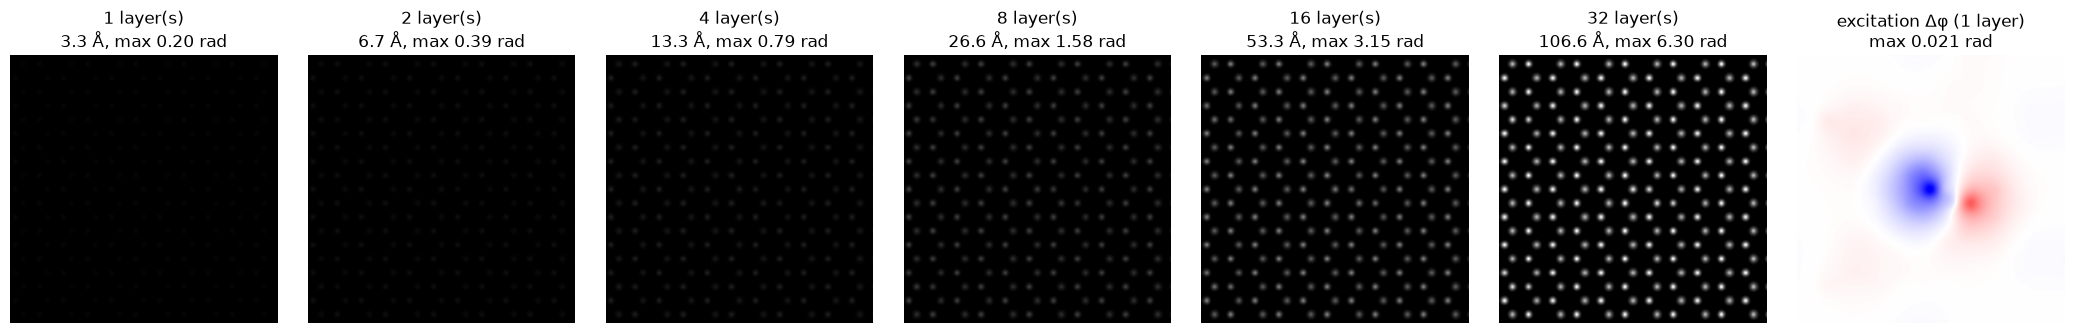

In [4]:
# What the beam actually sees, as a function of thickness
fig, axs = plt.subplots(1, len(N_LAYERS_SWEEP) + 1, figsize=(3 * (len(N_LAYERS_SWEEP) + 1), 3.2))
for ax, n in zip(axs, N_LAYERS_SWEEP):
    ax.imshow(n * base_phase, cmap="gray", vmin=0, vmax=max(N_LAYERS_SWEEP) * base_phase.max())
    ax.set_title(f"{n} layer(s)\n{n * D_INTERLAYER:.1f} Å, max {n * base_phase.max():.2f} rad")
    ax.axis("off")
axs[-1].imshow(delta_phi_gt, cmap="bwr", vmin=-0.02, vmax=0.02)
axs[-1].set_title(f"excitation Δφ (1 layer)\nmax {np.abs(delta_phi_gt).max():.3f} rad")
axs[-1].axis("off")
plt.tight_layout()

## Multislice sweep

Two full scans per thickness (light-off stack and light-on stack), then interlaced. Diffraction
patterns come out of abTEM normalised to unit total intensity, which is the convention
`method_wrappers` expects.

In [5]:
sims = {}
mask = None
extent = tuple(float(e) for e in stack_potential(1).extent)

for n in N_LAYERS_SWEEP:
    t0 = time.time()
    meas_off = simulate_scan(stack_potential(n))
    meas_on = simulate_scan(stack_potential(n, excited_layer=EXCITED_LAYER))
    dk = float(meas_off.sampling[0])

    if n == N_LAYERS_SWEEP[0]:
        print(f"realised scan sampling {meas_off._area_per_pixel ** 0.5:.4f} Å -> "
              + ", ".join(f"{d:.0e} e/Å² = {d * meas_off._area_per_pixel:,.0f} e/pattern"
                          for d in DOSES if d is not None))

    for k, dose in enumerate(DOSES):
        # independent noise realisations for the off and on cubes
        off_cube = to_cube(meas_off, dose, seed=None if dose is None else NOISE_SEED + 2 * k)
        on_cube = to_cube(meas_on, dose, seed=None if dose is None else NOISE_SEED + 2 * k + 1)

        if mask is None:
            mask = checkerboard_mask(off_cube.shape[:2])

        sims[(n, dose)] = dict(
            merged=interlace(off_cube, on_cube, mask),
            dk=dk,
            extent=extent,
            thickness=n * D_INTERLAYER,
        )
        del off_cube, on_cube

    del meas_off, meas_on
    print(f"n={n:2d}  t={n * D_INTERLAYER:5.1f} Å  cube {sims[(n, DOSES[0])]['merged'].shape}  "
          f"dk={dk:.4f} 1/Å  [{time.time() - t0:.0f} s]")

realised scan sampling 0.1497 Å -> 1e+06 e/Å² = 22,399 e/pattern


n= 1  t=  3.3 Å  cube (162, 162, 64, 64)  dk=0.0415 1/Å  [58 s]


n= 2  t=  6.7 Å  cube (162, 162, 64, 64)  dk=0.0415 1/Å  [72 s]


n= 4  t= 13.3 Å  cube (162, 162, 64, 64)  dk=0.0415 1/Å  [102 s]


n= 8  t= 26.6 Å  cube (162, 162, 64, 64)  dk=0.0415 1/Å  [160 s]


n=16  t= 53.3 Å  cube (162, 162, 64, 64)  dk=0.0415 1/Å  [276 s]


n=32  t=106.6 Å  cube (162, 162, 64, 64)  dk=0.0415 1/Å  [515 s]


## Reconstruction

For each thickness:

- **baseband SSB** — the ordinary reconstruction, which returns the (thickness-scaled) mean object;
- **demodulated SSB, notebook-04 form** — `fftshift` the scan-FFT of the vBF stack so the
  Nyquist carrier lands on DC, then SSB as usual and take `.obj` (mean of per-BF-pixel phases);
- **demodulated SSB, closed form** — `method_wrappers.direct_ssb`, which reconstructs the baseband
  and carrier fields *coherently* as complex objects $\bar{O}$, $\delta O$ and returns
  $\Delta\phi = 2\arctan\,\mathrm{Im}(\delta O/\bar{O})$.

In [6]:
def build_ptycho(entry):
    dataset = Dataset4d.from_array(
        entry["merged"],
        sampling=(SCAN_STEP_SIZE, SCAN_STEP_SIZE, entry["dk"], entry["dk"]),
        units=("A", "A", "A^-1", "A^-1"),
    )
    return DirectPtychography.from_dataset4d(
        dataset,
        energy=ACC_VOLTAGE,
        semiangle_cutoff=PROBE_SEMIANGLE,
        aberration_coefs={"defocus": PROBE_DEFOCUS},
        verbose=False,
    )


def reconstruct_entry(entry):
    ptycho = build_ptycho(entry)

    # baseband: the ordinary SSB object
    ptycho.reconstruct(deconvolution_kernel="ssb", verbose=False)
    obj_mean = ptycho.obj.copy()

    # notebook-04 demodulation: shift the Nyquist carrier onto DC, re-deconvolve
    ptycho._preprocess()
    ptycho._vbf_fourier = torch.fft.fftshift(ptycho._vbf_fourier, dim=(-1, -2))
    ptycho.reconstruct(deconvolution_kernel="ssb", verbose=False)
    obj_delta_nb04 = ptycho.obj.copy()

    # closed-form estimator (scan_step is the *coarse* per-channel step = 2x native)
    scan_params = dict(
        probe_energy=ACC_VOLTAGE,
        probe_semiangle=PROBE_SEMIANGLE,
        probe_defocus=PROBE_DEFOCUS,
        scan_step=2 * SCAN_STEP_SIZE,
    )
    out = mw.direct_ssb(entry["merged"], mask, scan_params)

    return dict(
        obj_mean=obj_mean,
        obj_delta_nb04=obj_delta_nb04,
        obj_delta_closed=out["delta_phi"],
        mean_object_phase=out["mean_object_phase"],
    )


def dose_label(dose):
    return "noise-free" if dose is None else f"{dose:.0e} e/Å²"


recons = {}
for key, entry in sims.items():
    t0 = time.time()
    recons[key] = reconstruct_entry(entry)
    print(f"n={key[0]:2d}  dose={dose_label(key[1]):>12}  done [{time.time() - t0:.0f} s]")

n= 1  dose=  noise-free  done [12 s]


n= 1  dose=  1e+06 e/Å²  done [12 s]


n= 2  dose=  noise-free  done [12 s]


n= 2  dose=  1e+06 e/Å²  done [12 s]


n= 4  dose=  noise-free  done [12 s]


n= 4  dose=  1e+06 e/Å²  done [13 s]


... (2 outputs left out)

n=16  dose=  noise-free  done [13 s]


n=16  dose=  1e+06 e/Å²  done [13 s]


n=32  dose=  noise-free  done [12 s]


n=32  dose=  1e+06 e/Å²  done [12 s]


## Ground truth comparison

The reconstruction lives on the scan grid (0.15 Å), the ground truth on the potential grid
(0.096 Å), so the ground truth is resampled onto the scan grid before comparing. Two numbers per
reconstruction: Pearson $r$ (does it still look like the excitation?) and the least-squares slope
against the ground truth (how much of the amplitude survives).

In [7]:
def gt_on_scan_grid(gt, shape, extent):
    rows = np.linspace(0.0, extent[0], shape[0]) / dx - 0.5
    cols = np.linspace(0.0, extent[1], shape[1]) / dy - 0.5
    grid = np.meshgrid(rows, cols, indexing="ij")
    return map_coordinates(gt, grid, order=1, mode="nearest")


def score(recon, gt):
    a = recon - recon.mean()
    g = gt - gt.mean()
    r = float((a * g).sum() / np.sqrt((a * a).sum() * (g * g).sum()))
    slope = float((a * g).sum() / (g * g).sum())
    return r, slope


shape = next(iter(recons.values()))["obj_delta_nb04"].shape
gt_scan = gt_on_scan_grid(delta_phi_gt, shape, extent)

scores = {}
for dose in DOSES:
    print(f"dose = {dose_label(dose)}")
    print(f"{'N':>3} {'t [Å]':>7} | {'r (nb04)':>9} {'amp':>7} | {'r (closed)':>11} {'amp':>7}")
    for n in N_LAYERS_SWEEP:
        r04, a04 = score(recons[(n, dose)]["obj_delta_nb04"], gt_scan)
        rcf, acf = score(recons[(n, dose)]["obj_delta_closed"], gt_scan)
        scores[(n, dose)] = dict(r_nb04=r04, amp_nb04=a04, r_closed=rcf, amp_closed=acf)
        print(f"{n:3d} {n * D_INTERLAYER:7.1f} | {r04:9.3f} {a04:7.3f} | {rcf:11.3f} {acf:7.3f}")
    print()

dose = noise-free
  N   t [Å] |  r (nb04)     amp |  r (closed)     amp
  1     3.3 |     0.871   0.091 |       0.871   0.183
  2     6.7 |     0.871   0.091 |       0.871   0.182
  4    13.3 |     0.870   0.091 |       0.871   0.180
  8    26.6 |     0.867   0.089 |       0.869   0.172
 16    53.3 |     0.855   0.082 |       0.855   0.153
 32   106.6 |     0.870   0.074 |       0.869   0.143

dose = 1e+06 e/Å²
  N   t [Å] |  r (nb04)     amp |  r (closed)     amp
  1     3.3 |     0.129   0.083 |       0.129   0.167
  2     6.7 |     0.123   0.080 |       0.123   0.160
  4    13.3 |     0.148   0.093 |       0.148   0.187
  8    26.6 |     0.148   0.094 |       0.145   0.180
 16    53.3 |     0.118   0.075 |       0.118   0.143
 32   106.6 |     0.101   0.065 |       0.102   0.128



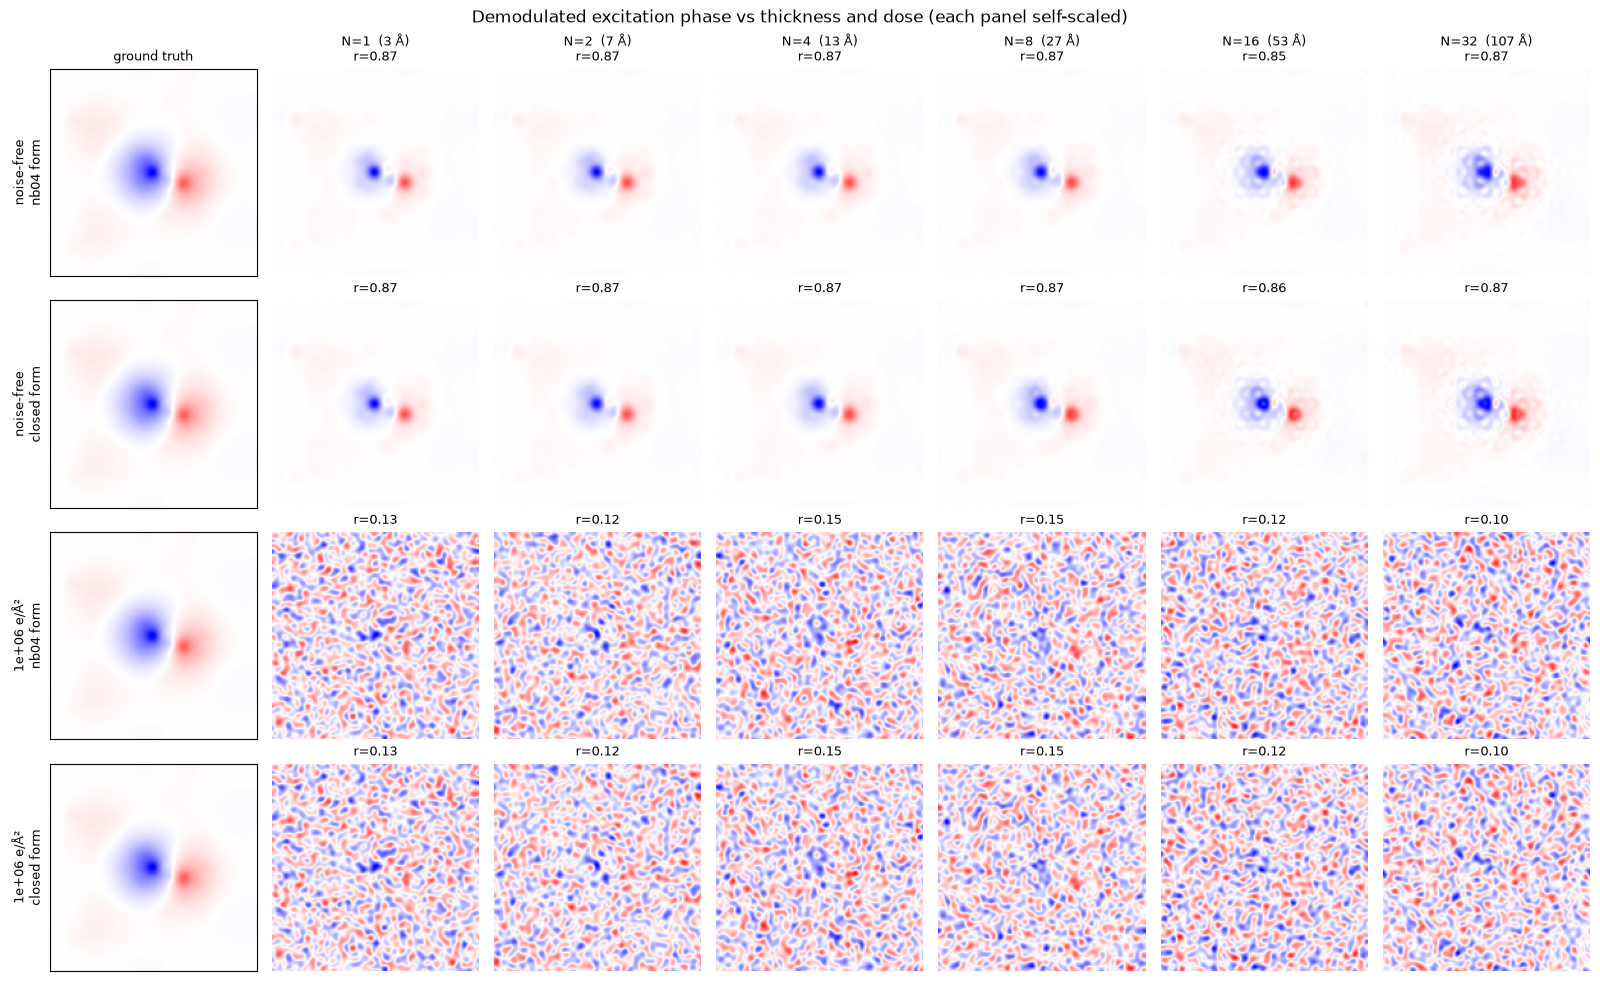

In [8]:
# Recovered excitation: rows = (noise-free, each finite dose) x estimator, cols = thickness
rows = [(dose, key, f"{dose_label(dose)}\n{'nb04' if key.endswith('nb04') else 'closed'} form")
        for dose in DOSES
        for key in ("obj_delta_nb04", "obj_delta_closed")]

ncols = len(N_LAYERS_SWEEP) + 1
fig, axs = plt.subplots(len(rows), ncols, figsize=(2.3 * ncols, 2.5 * len(rows)))

for row, (dose, key, label) in enumerate(rows):
    axs[row, 0].imshow(gt_scan, cmap="bwr", vmin=-0.02, vmax=0.02)
    axs[row, 0].set_ylabel(label, fontsize=9)
    axs[row, 0].set_xticks([]); axs[row, 0].set_yticks([])
    if row == 0:
        axs[row, 0].set_title("ground truth", fontsize=9)

    score_key = "r_nb04" if key.endswith("nb04") else "r_closed"
    for col, n in enumerate(N_LAYERS_SWEEP, start=1):
        img = recons[(n, dose)][key]
        v = np.abs(img).max()
        axs[row, col].imshow(img, cmap="bwr", vmin=-v, vmax=v)
        axs[row, col].axis("off")
        axs[row, col].set_title(
            (f"N={n}  ({n * D_INTERLAYER:.0f} Å)\n" if row == 0 else "")
            + f"r={scores[(n, dose)][score_key]:.2f}",
            fontsize=9,
        )

plt.suptitle("Demodulated excitation phase vs thickness and dose (each panel self-scaled)", fontsize=12)
plt.tight_layout()

dose = noise-free
  N   t [Å] |      r     amp
  1     3.3 |  0.900   0.550
  2     6.7 |  0.900   0.551
  4    13.3 |  0.900   0.548
  8    26.6 |  0.897   0.513
 16    53.3 |  0.895   0.367
 32   106.6 |  0.897   0.129

dose = 1e+06 e/Å²
  N   t [Å] |      r     amp
  1     3.3 |  0.899   0.550
  2     6.7 |  0.900   0.551
  4    13.3 |  0.899   0.547
  8    26.6 |  0.897   0.513
 16    53.3 |  0.895   0.366
 32   106.6 |  0.897   0.129



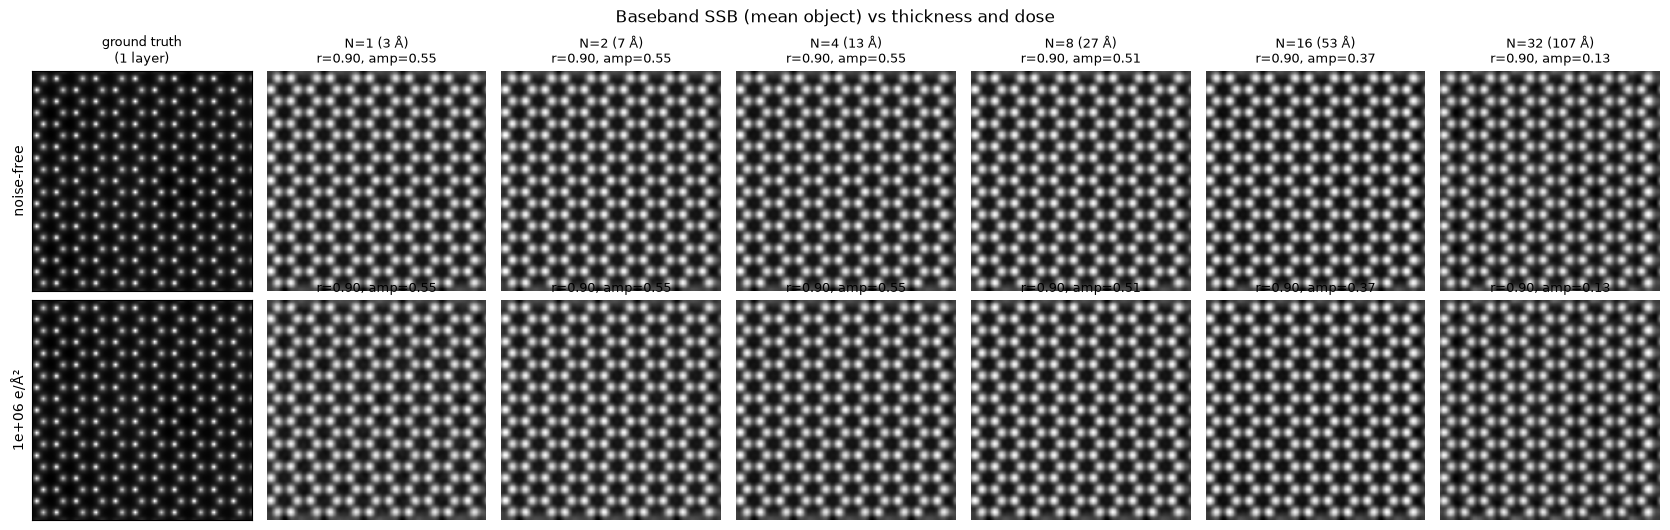

In [9]:
# The baseband object over the same sweep -- SSB's own breakdown, for reference.
# Scored against N x (single-layer phase), i.e. against the *kinematic* expectation,
# so `amp` < 1 is exactly the dynamical saturation of the recovered phase.
baseband = {}
for dose in DOSES:
    print(f"dose = {dose_label(dose)}")
    print(f"{'N':>3} {'t [Å]':>7} | {'r':>6} {'amp':>7}")
    for n in N_LAYERS_SWEEP:
        baseband[(n, dose)] = score(
            recons[(n, dose)]["obj_mean"], gt_on_scan_grid(n * base_phase, shape, extent)
        )
        print(f"{n:3d} {n * D_INTERLAYER:7.1f} | {baseband[(n, dose)][0]:6.3f} {baseband[(n, dose)][1]:7.3f}")
    print()

fig, axs = plt.subplots(len(DOSES), len(N_LAYERS_SWEEP) + 1,
                        figsize=(2.4 * (len(N_LAYERS_SWEEP) + 1), 2.7 * len(DOSES)),
                        squeeze=False)
for row, dose in enumerate(DOSES):
    axs[row, 0].imshow(gt_on_scan_grid(base_phase, shape, extent), cmap="gray")
    axs[row, 0].set_ylabel(dose_label(dose), fontsize=10)
    axs[row, 0].set_xticks([]); axs[row, 0].set_yticks([])
    if row == 0:
        axs[row, 0].set_title("ground truth\n(1 layer)", fontsize=9)
    for col, n in enumerate(N_LAYERS_SWEEP, start=1):
        axs[row, col].imshow(recons[(n, dose)]["obj_mean"], cmap="gray")
        r, amp = baseband[(n, dose)]
        axs[row, col].set_title(
            (f"N={n} ({n * D_INTERLAYER:.0f} Å)\n" if row == 0 else "") + f"r={r:.2f}, amp={amp:.2f}",
            fontsize=9,
        )
        axs[row, col].axis("off")
plt.suptitle("Baseband SSB (mean object) vs thickness and dose", fontsize=12)
plt.tight_layout()

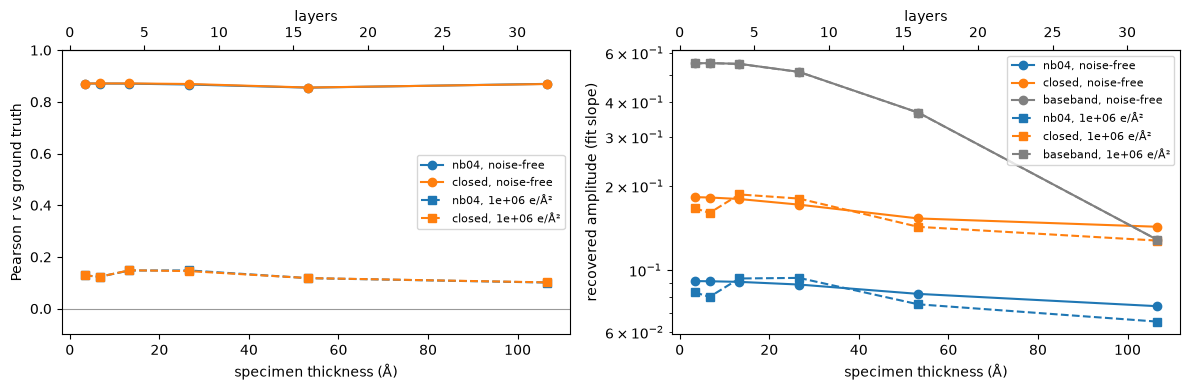

In [10]:
thickness = np.array([n * D_INTERLAYER for n in N_LAYERS_SWEEP])
styles = {None: dict(ls="-", marker="o"), DOSES[-1]: dict(ls="--", marker="s")}

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for dose in DOSES:
    st = styles.get(dose, dict(ls=":", marker="^"))
    axs[0].plot(thickness, [scores[(n, dose)]["r_nb04"] for n in N_LAYERS_SWEEP],
                color="C0", label=f"nb04, {dose_label(dose)}", **st)
    axs[0].plot(thickness, [scores[(n, dose)]["r_closed"] for n in N_LAYERS_SWEEP],
                color="C1", label=f"closed, {dose_label(dose)}", **st)
    axs[1].plot(thickness, [abs(scores[(n, dose)]["amp_nb04"]) for n in N_LAYERS_SWEEP],
                color="C0", label=f"nb04, {dose_label(dose)}", **st)
    axs[1].plot(thickness, [abs(scores[(n, dose)]["amp_closed"]) for n in N_LAYERS_SWEEP],
                color="C1", label=f"closed, {dose_label(dose)}", **st)
    axs[1].plot(thickness, [abs(baseband[(n, dose)][1]) for n in N_LAYERS_SWEEP],
                color="0.5", label=f"baseband, {dose_label(dose)}", **st)

axs[0].axhline(0, color="0.6", lw=0.8)
axs[0].set_ylabel("Pearson r vs ground truth")
axs[0].set_ylim(-0.1, 1.0)
axs[1].set_ylabel("recovered amplitude (fit slope)")
axs[1].set_yscale("log")
for ax in axs:
    ax.set_xlabel("specimen thickness (Å)")
    ax.legend(fontsize=8)
    secax = ax.secondary_xaxis("top", functions=(lambda t: t / D_INTERLAYER, lambda n: n * D_INTERLAYER))
    secax.set_xlabel("layers")
plt.tight_layout()

## Where does the carrier go?

Notebook 04 (cell 32) collapsed $|\tilde{G}(\mathbf{Q},k)|$ along the scan-frequency diagonal to
show the excitation sideband sitting at the checkerboard carrier. Repeating that per thickness
shows whether the sideband is being buried by dynamical scattering or merely attenuated; repeating
it per dose puts the Poisson noise floor on the same axes, which is what actually sets the
detection limit for the carrier.

/tmp/ipykernel_1956554/2687265971.py:18: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  spectrum = np.abs(ptycho._vbf_fourier).sum(0).numpy()[strip]


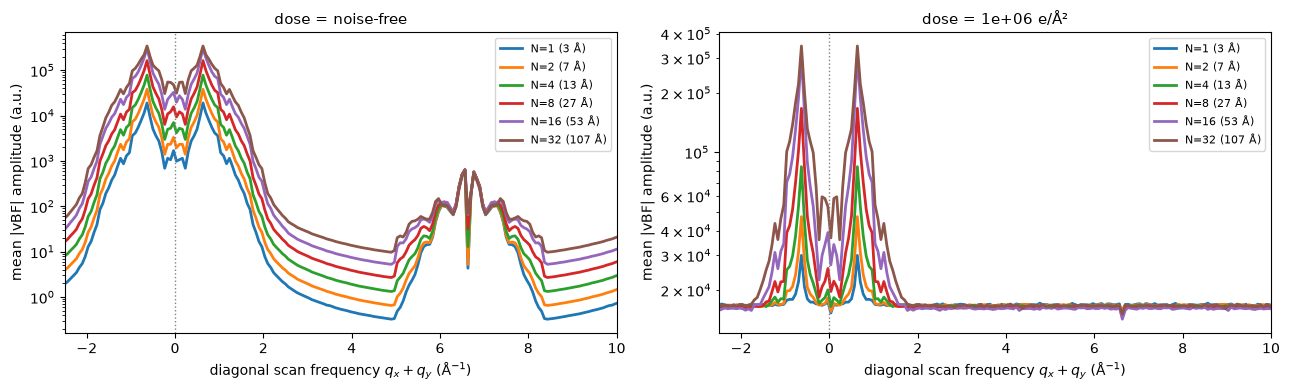

In [11]:
strip_size = 3
fig, axs = plt.subplots(1, len(DOSES), figsize=(6.5 * len(DOSES), 4), squeeze=False)

for ax, dose in zip(axs[0], DOSES):
    for n in N_LAYERS_SWEEP:
        ptycho = build_ptycho(sims[(n, dose)])   # fresh: _preprocess runs in __init__
        q_x, q_y = ptycho._return_upsampled_qgrid()
        q_x, q_y = np.asarray(q_x), np.asarray(q_y)

        dq = np.median(np.diff(np.unique(q_x)))
        q_s = dq * len(np.unique(q_x))

        q = np.mod(q_x + q_y, 2 * q_s)
        strip = np.abs(q_x - q_y) / np.sqrt(2) <= strip_size * dq
        q = np.concatenate((q[strip] - 2 * q_s, q[strip]))

        edges = np.linspace(-q_s, 2 * q_s, 301)
        spectrum = np.abs(ptycho._vbf_fourier).sum(0).numpy()[strip]
        collapsed = binned_statistic(q, np.tile(spectrum, 2), bins=edges).statistic
        q_plot = (edges[:-1] + edges[1:]) / 2

        ax.plot(q_plot, collapsed, lw=2, label=f"N={n} ({n * D_INTERLAYER:.0f} Å)")
        del ptycho

    ax.axvline(0, color="0.5", ls=":", lw=1)
    ax.set_yscale("log")
    ax.set_xlim(-2.5, 10)
    ax.set_title(f"dose = {dose_label(dose)}", fontsize=11)
    ax.set_xlabel(r"diagonal scan frequency $q_x + q_y$ ($\mathrm{\AA}^{-1}$)")
    ax.set_ylabel("mean |vBF| amplitude (a.u.)")
    ax.legend(fontsize=8)
plt.tight_layout()

## Does it matter *which* layer is excited?

With the excited layer at the entrance surface, its signal has to propagate through the whole
remaining stack before it reaches the detector. Putting the same excited layer at the **exit**
surface instead isolates how much of the loss is propagation of the excitation itself versus the
incoherence of the probe after traversing the stack.

In [12]:
n_deep = N_LAYERS_SWEEP[-1]

t0 = time.time()
meas_off = simulate_scan(stack_potential(n_deep))
meas_on_exit = simulate_scan(stack_potential(n_deep, excited_layer=n_deep - 1))
print(f"exit-surface excitation, N={n_deep}: [{time.time() - t0:.0f} s]")

exit_scores = {}
for k, dose in enumerate(DOSES):
    entry_exit = dict(
        merged=interlace(
            to_cube(meas_off, dose, seed=None if dose is None else NOISE_SEED + 100 + 2 * k),
            to_cube(meas_on_exit, dose, seed=None if dose is None else NOISE_SEED + 101 + 2 * k),
            mask,
        ),
        dk=float(meas_off.sampling[0]),
        extent=extent,
        thickness=n_deep * D_INTERLAYER,
    )
    recon_exit = reconstruct_entry(entry_exit)
    exit_scores[dose] = dict(
        recon=recon_exit,
        exit=score(recon_exit["obj_delta_closed"], gt_scan),
        entrance=score(recons[(n_deep, dose)]["obj_delta_closed"], gt_scan),
    )
    e_r, e_a = exit_scores[dose]["entrance"]
    x_r, x_a = exit_scores[dose]["exit"]
    print(f"N={n_deep} ({n_deep * D_INTERLAYER:.0f} Å)  dose={dose_label(dose):>12}  "
          f"entrance: r={e_r:+.3f} amp={e_a:.4f}   |   exit: r={x_r:+.3f} amp={x_a:.4f}")
    del entry_exit

del meas_off, meas_on_exit

exit-surface excitation, N=32: [504 s]


N=32 (107 Å)  dose=  noise-free  entrance: r=+0.869 amp=0.1430   |   exit: r=+0.779 amp=0.0570


N=32 (107 Å)  dose=  1e+06 e/Å²  entrance: r=+0.102 amp=0.1276   |   exit: r=+0.060 amp=0.0740


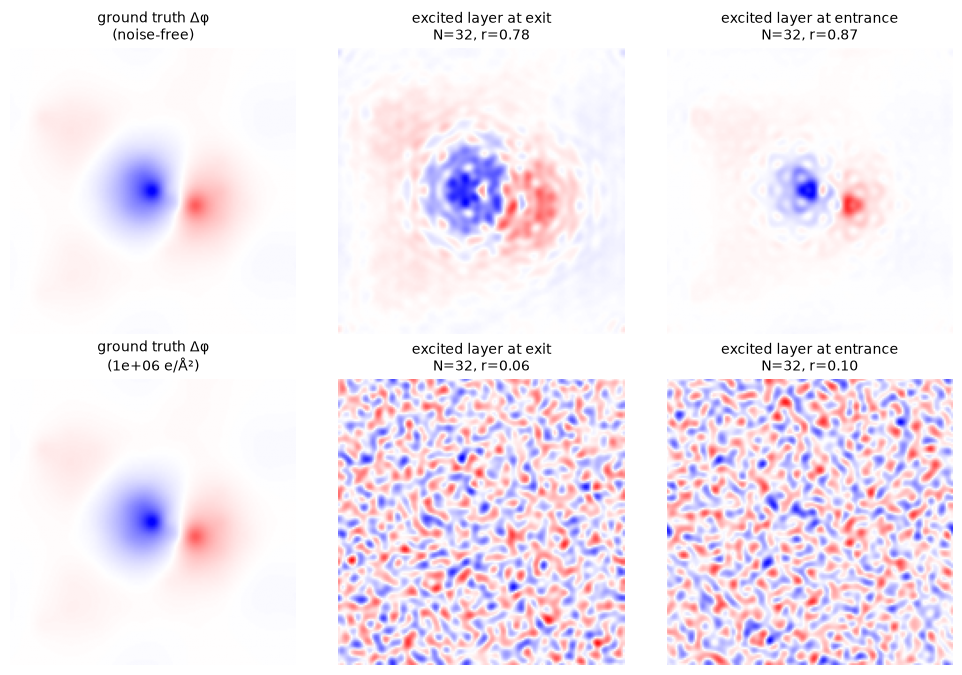

In [13]:
fig, axs = plt.subplots(len(DOSES), 3, figsize=(10, 3.4 * len(DOSES)), squeeze=False)
for row, dose in enumerate(DOSES):
    panels = (
        (gt_scan, "ground truth Δφ", None),
        (exit_scores[dose]["recon"]["obj_delta_closed"], "excited layer at exit", exit_scores[dose]["exit"][0]),
        (recons[(n_deep, dose)]["obj_delta_closed"], "excited layer at entrance", exit_scores[dose]["entrance"][0]),
    )
    for ax, (img, ttl, r) in zip(axs[row], panels):
        v = 0.02 if r is None else np.abs(img).max()
        ax.imshow(img, cmap="bwr", vmin=-v, vmax=v)
        ax.set_title(ttl + (f"\nN={n_deep}, r={r:.2f}" if r is not None else ""), fontsize=10)
        ax.axis("off")
    axs[row, 0].set_title(f"{panels[0][1]}\n({dose_label(dose)})", fontsize=10)
plt.tight_layout()

## Findings

**Thickness is not the limit; dose is.**

*Noise-free.* Over 3.3 → 107 Å (1 → 32 layers) the demodulated excitation barely degrades:
Pearson $r$ = 0.871 → 0.869, and the recovered amplitude falls only 22% (0.183 → 0.143, closed
form). The *baseband* reconstruction over the very same data shows textbook dynamical saturation
in the same range — scored against $N\times$(single-layer phase), its amplitude collapses 0.550 →
0.129, a 77% loss. So the differential channel is roughly **three times more thickness-tolerant
than SSB itself**.

The carrier spectrum says why. Collapsed along the scan-frequency diagonal, the baseband peaks grow
by ~1.5 decades from N=1 to N=32 while **the carrier peak at $q_x+q_y \approx 6.6\ \mathrm{Å}^{-1}$
is essentially unchanged at every thickness**. With the excited layer at the entrance surface the
probe reaching it is the vacuum probe no matter how much material is underneath; thickness only
attenuates the excitation on the way *out*. What degrades is the carrier-to-baseband contrast
ratio, not the carrier.

*At $10^6$ e/Å² (≈22,400 electrons per diffraction pattern).* The demodulated reconstruction
collapses to $r \approx 0.10$–$0.15$ **at every thickness, N=1 included** — so this is not a
thickness effect at all. At the same time the baseband object is untouched by the noise
($r$ = 0.899 vs 0.900 noise-free; amplitudes identical to three decimals). The ordinary SSB object
is effectively noise-free at a dose that destroys the differential channel.

Two things make the differential channel so much more fragile:
- the excitation is a ~1% modulation (0.02 rad against a 0.2–3 rad object), and
- it is carried at the **scan Nyquist frequency**, where the SSB transfer is weakest but Poisson
  noise is white and unattenuated.

The diagonal-strip spectrum makes this quantitative: the shot-noise floor sits at ~1.5$\times10^4$
in the same units where the carrier peak is ~700, i.e. the carrier is buried **~20× below the noise
floor**.

**The estimator is buried, not biased.** The fitted amplitude is almost unchanged by noise
(0.167 at $10^6$ e/Å² vs 0.183 noise-free, N=1) while $r$ drops by ~7×. The signal is still there
with the right magnitude — it is simply swamped. Closing the gap to $r \approx 0.85$ needs roughly
two orders of magnitude more dose ($\sim10^8$ e/Å²), which is not viable for a beam-sensitive
specimen. The practical routes are therefore *not* more dose: coarser scan sampling (which moves
the carrier away from the SSB transfer cut-off), many repeats averaged coherently, or an estimator
that does not place the signal at Nyquist.

**Estimator choice does not affect fidelity.** The notebook-04 form and the closed form give
identical $r$ to within 0.003 everywhere; they differ by a near-constant factor ~2 in amplitude
(the closed form's $2\arctan$ versus the mean-of-phase-angles). Use the closed form for a
calibrated amplitude, but it buys no robustness.

**Entrance vs exit placement crosses over with thickness.** At N=16 (53 Å) putting the excited
layer at the exit surface is *better* ($r$ = 0.90 vs 0.86) — no out-propagation to blur it. At N=32
(107 Å) it is *worse* ($r$ = 0.78 vs 0.87, amplitude 0.057 vs 0.143): by then the probe arriving at
the exit surface is so channelled and spread that it couples weakly to the excitation. Which
surface is favourable depends on thickness.

**Caveats.** Every layer is an exact copy of the same projected potential with no AA′ registry
shift, which maximises channelling — if anything a pessimistic thickness test. Only the shot noise
of the electrons is modelled: no detector noise, drift, or partial coherence.